# Main Imports

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import copy

# Short Questions

## 1. A Couple of examples of plots

### Jake Vanderplas book

#### 04.08 Multiple subplots

Having multiple subplots can be useful to organize data, the main conventional way to do so is by using `plt.subplot` or `plt.subplots`, discretizing a plot into a grid of multiple subplots

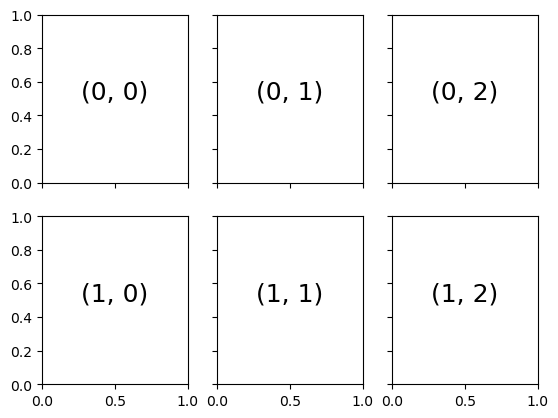

In [59]:
grid = plt.GridSpec(2, 3, wspace=0.4, hspace=0.3)

fig, ax = plt.subplots(2, 3, sharex='col', sharey='row')

for i in range(2):
    for j in range(3):
        ax[i, j].text(0.5, 0.5, str((i, j)),
                      fontsize=18, ha='center')

Additionally, using `plt.GridSpec` allows you to freely allocate space for different `plt.subplot`.

#### 04.09 Text and Annotation

Assuming we define a graph using for instance `fig, ax = plt.subplots(figsize=(X, Y))`, then, one can use `plt.text` or `ax.text` to add text relative to some data point.

Other options such as a combination of `plt.arrow` and `plt.annotate` allows more control with respect to the annotating text (i.e. putting the annotation in a certain manner, and linking some data point and the text with an arrow).

#### 04.10 Customizing Ticks

In matplotlib, ticks represent the different "markers" (such as the scale legend on axes for instance) used in plots.

Matplotlib uses "major" (the main ones, bigger, "essential") and "minor" (situational) tickmarks.

When displaying some plots, one can remove the abscissa and ordinate marking ticks using (targetting major tickmarks):

```
ax = plt.axes()
ax.yaxis.set_major_locator(plt.NullLocator())
ax.xaxis.set_major_formatter(plt.NullFormatter())
```


Additionally, When using different subplots, one can use:

```
for axi in ax.flat:
    axi.xaxis.set_major_locator(plt.MaxNLocator(3))
    axi.yaxis.set_major_locator(plt.MaxNLocator(3))
```

to only display 3 tickmark measure per graph (think of only displaying 3 abscissa or ordinate main values on the graph's scale).

Using `plt.MultipleLocator` allows more flexibility when it comes to how many (and which exact values of) tickmarks one wants to display.

More examples of options on the book or on the main [documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axis.Axis.set_major_locator.html). 

#### 04.11 Settings and Stylesheets

Matplotlib gives a decent range of customization. Namely, using `rcParams` changes the default parameters, i.e. the default colors of different components, but also the default style of lines, ticks, etc.

One can also use one of the predefined set of styles, in `plt.style.available` inside a `plt.style.context` method (specifics can also be changed using dictionaries and/or using some `rcParams` components). Running the code below will give you one of the random style presets with examples in basic plotting, histogram and scatter plots.

Nice, you got the dark_background style!


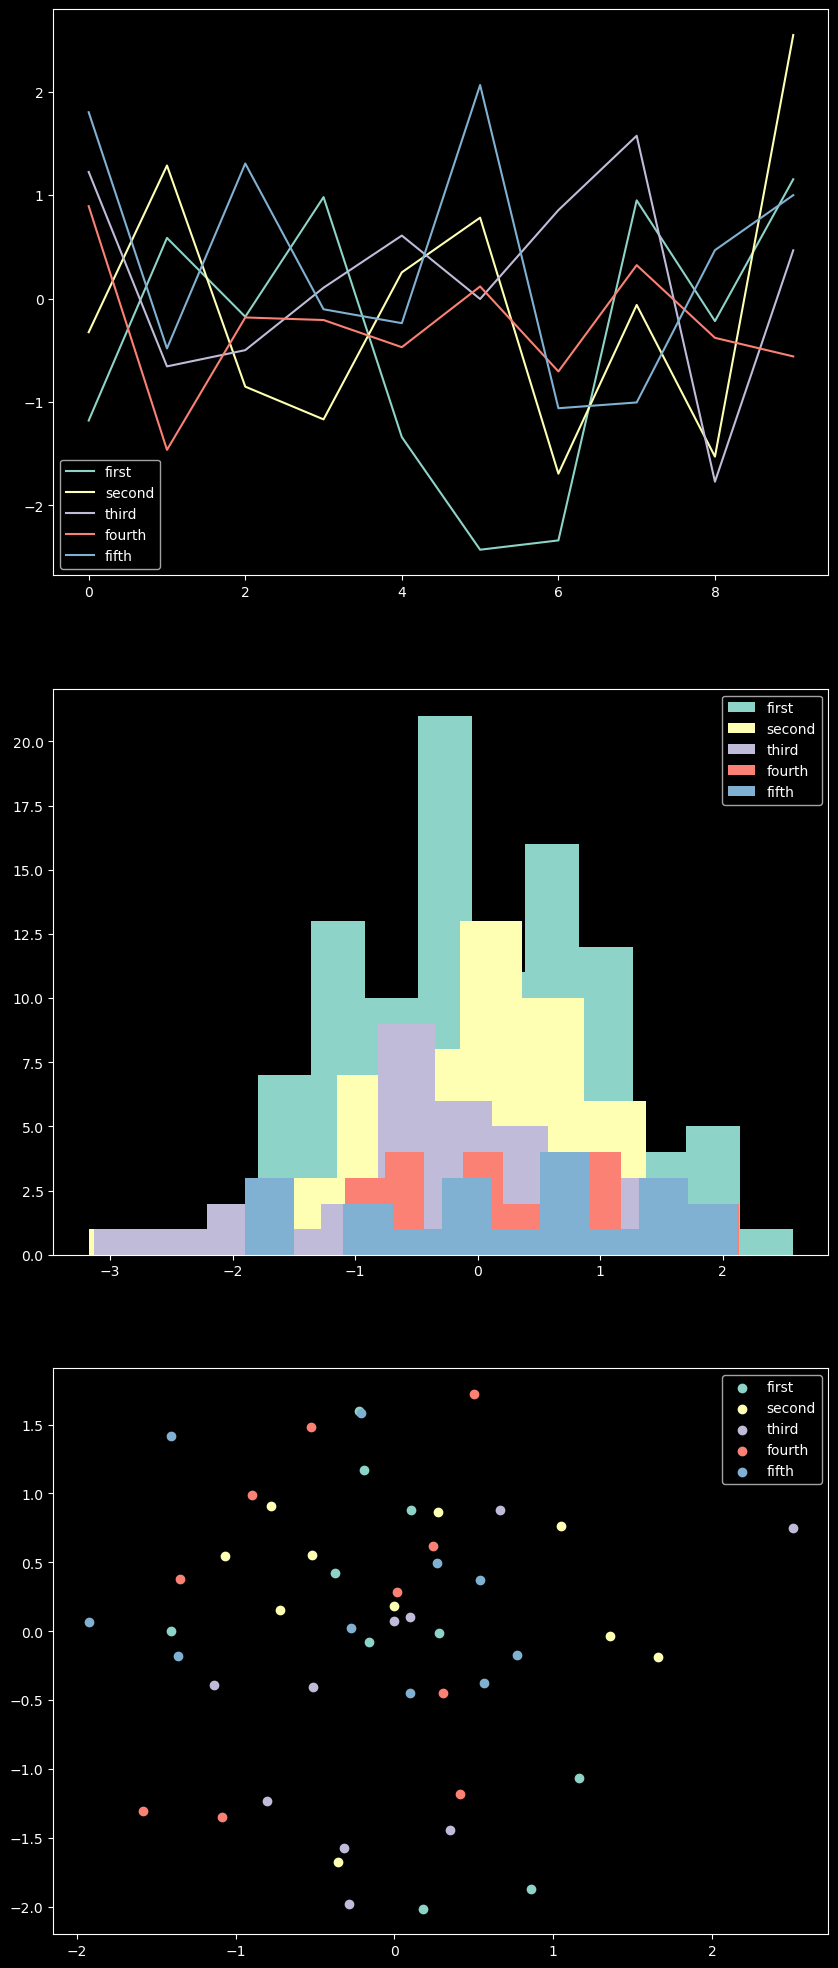

In [60]:
with plt.style.context(style := str(np.random.choice(plt.style.available))):
    print(f"Nice, you got the {style} style!")
    fig, ax = plt.subplots(3, 1, figsize=(10, 25))
    for i in range(5):
        ax[0].plot(np.random.randn(10))
        ax[1].hist(np.random.randn(100 // (i+1)))
        ax[2].scatter(np.random.randn(10), np.random.randn(10))
    ax[0].legend(['first', 'second', 'third', 'fourth', 'fifth'])
    ax[1].legend(['first', 'second', 'third', 'fourth', 'fifth'])
    ax[2].legend(['first', 'second', 'third', 'fourth', 'fifth'])
    

#### 04.12 Three-Dimensional Plotting

Some matplotlib additional library allows for 3D-plotting. The only main fundamental change in plotting stems in a new `z` value to take into account when plotting.

One can plot predefined functions in numpy, or can define their own and then plot them directly.

For instance, one can plot functions in 3D as such

Text(0.5, 0, 'z')

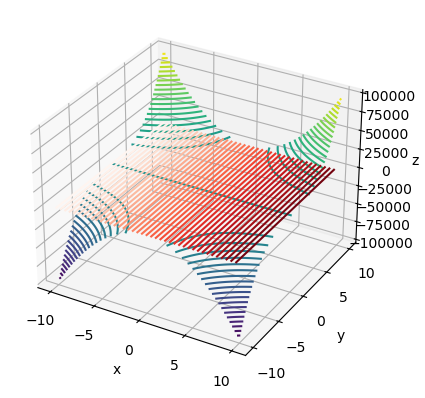

In [61]:
from mpl_toolkits import mplot3d

def f(x, y):
    return x + 1

def g(x, y):
    return y**3 * x**2

x, y = np.linspace(-10, 10, 100), np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x, y)

Z1 = f(X, Y)
Z2 = g(X, Y)

fig = plt.figure()
ax = plt.axes(projection='3d')
ax.contour3D(X, Y, Z1, 40, cmap='Reds')
ax.contour3D(X, Y, Z2, 40, cmap='viridis')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

# 2. Good Practices

### A. Copying

Python's `=` assigning values between variables does not create distinct copies. By default, this results in shallow copies, where one variable's object gets "intertwined" with another. This is because `=` only reassigns pointer values. Here, changing x also impacts y:

In [62]:
x = [0] * 10
y = x

x[0] = 1
y

[1, 0, 0, 0, 0, 0, 0, 0, 0, 0]

One may prefer to create a shallow copy of x before assigning it to y, so that y is resilient to x's changes:

In [82]:
x = [0] * 10
y = x.copy()

x[0] = 1
y

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

However, shallow copies are not that resilient, here is an example where y gets changed:

In [64]:
x = [[0]*3, [0]*3]
y = x.copy()

x[0][0] = 1
y

[[1, 0, 0], [0, 0, 0]]

One may even do a deep copy (assigning memory for an entire copy of an object):

In [65]:
x = [0] * 10
y = copy.deepcopy(x)

x[0] = 1
y

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [84]:
x = [[0]*3, [0]*3]
y = copy.deepcopy(x)

x[0][0] = 1
y #Now y is fully unchanged, full zeros

[[0, 0, 0], [0, 0, 0]]

### B. Object and memory management

When working with limited memory or time, using some methods may be detrimental. With lists for instance, using + creates a new list instance.

In [66]:
start_time = time.time()

x = [0] * 100000
y = [0] * 100000000

x += y

print(time.time() - start_time)

0.41234493255615234


In [67]:
start_time = time.time()

x = [0] * 100000
y = [0] * 100000000

for e in y:
    x.append(e)

print(time.time() - start_time)

2.461451768875122


In [68]:
start_time = time.time()

x = [0] * 100000
y = [0] * 100000000

x.extend(y)

print(time.time() - start_time)

0.5494692325592041


Of course, efficiency here is space-dependent. Take a smaller y, and one will get different results.

In [69]:
start_time = time.time()

x = [0] * 100000
y = [0] * 10

x += y

print(time.time() - start_time)

0.1364293098449707


In [70]:
start_time = time.time()

x = [0] * 100000
y = [0] * 10

for e in y:
    x.append(e)

print(time.time() - start_time)

0.0001392364501953125


In [71]:
start_time = time.time()

x = [0] * 100000
y = [0] * 10

x.extend(y)

print(time.time() - start_time)

0.0001010894775390625


With a bigger y, the append method (in a for loop) was losing, probably because of variable attributions with e. With a smaller y though, creating a new list through + was simply too inefficient. Extend seems to be the preferred candidate. Of course, each of these methods can be twisted for one's own needs, especially because of space-dependency (one may need to create a whole new array, etc.).

### C. Calibrating with respect to machine precision

Float operations are always odd, especially at extreme scales. One may need to choose a more precise float scale if they want more precision (although using more space).

In [72]:
A1 = 0.000000003 - 0.000000001
A1

1.9999999999999997e-09

In [73]:
A2 = np.float128(0.000000003) - np.float128(0.000000001)
A2

np.longdouble('1.9999999999999999178e-09')

In [74]:
A2 - A1

np.longdouble('2.0679515313825691872e-25')

Here, the precision is in the 10**(-25), which can be tolerable for some, and not for others. It's important to keep these kind of discrepancies in mind.

### D. When in doubt, use NumPy, it's (most of the time, on complex problems) faster

NumPy handles array operations better, especially operations between arrays or complex functions. A simple example with x**2 (not even counting np.exp, np.sin, etc.).

In [75]:
def f(x):
    return x**2

In [76]:
# bad example
time_start = time.time()

a = [f(i) for i in range(100001)]

print(n1 := time.time() - time_start)

0.005156278610229492


In [77]:
# good example
time_start = time.time()

a = f(np.linspace(0, 100000, 100001))

print(n2 := time.time() - time_start)

0.000766754150390625


In [78]:
print(f"Time diff: {n1 - n2}")

Time diff: 0.004389524459838867


This may count for optimization, over even larger arrays and more complex functions.

### E. Please, make functions if you reuse your code, do not repeat yourself.

Copying and pasting raw code leads to more chances of making spaghetti code :/

Bad example

In [79]:
X = 0
X += 18
X *= 4
X += 18
print(f"X = {X}")

Y = 1
Y *= 3
Y += 12
Y *= 3
Y += 12
Y *= 3
Y += 12
Y *= 3
Y += 12
Y *= 3
Y += 12
print(f"Y = {Y}")

# ...

X = 90
Y = 1695


Instead of doing (better example):

In [80]:
def arith_geo(x, a, b, n):
    if n <= 0:
        return x
    return arith_geo(a*x + b, a, b, n - 1)

print(f"X = {arith_geo(0, 4, 18, 2)}")
print(f"Y = {arith_geo(1, 3, 12, 5)}")

X = 90
Y = 1695


### F. Exceptions shenanigans, debugging

Try and except are pretty useful overall, but not filtering by specific exceptions can limit the way someone uses exceptions (bad example):

In [ ]:
try:
    x = 1
    x += "e"
    print("succesful")
    
except Exception as err:
    print(f"damn, {err}")

damn, unsupported operand type(s) for +=: 'int' and 'str'


As one can create fallback situations (or corrections, or temporary solutions...) when it comes to filtering with respect to certain exception types (better example).

In [ ]:
try:
    x = 1
    x += "e"
    print("succesful")
    
except TypeError as err:
    print(f"check this out, despite {err}")
    x += int("e", 16)
    print(x)
    
except Exception as err:
    print(f"damn, {err}")

check this out, despite unsupported operand type(s) for +=: 'int' and 'str'
15


### G. Glimpses of dynamic programming (factorial)

In [136]:
def factorial(x):
    if x <= 1:
        return 1
    return x * factorial(x - 1)

time_start = time.time()
print(factorial(1001))
print(n2 := time.time() - time_start)
# print(f"Time diff: {n1 - n2}")

4027896473371708673172461363569269897050942390749253471763437103403684509110276496126362526954563742052804685988073932546902985398678033674602251534996145355884219285911608336787424513549159212522992854569462713969958504379595406450196963727411427873474502813253243738244563002268716094314978269894891095227257916911679456985092824215386329665233766798918236969009820752231882794651940654891114985865229975733078380579349947062129342914778822214649140587458081797951300189691756057398242372476845127901696480137781586615203849163572855472196603375040679100879363015808746623675439212889882082619448341783691698056824894205040383345293891778450896795460750233058540061412562886338200799403953292515637883994046529021545193029283651694523835310307556845785038514881540923235761503115693258911901059261187616071002868279304729449132724208250789121587415898501360170308879754529224348896887758833869778252159044236824789433138060721440974324186958074125712923087398024810894070025239550801481840628104475

In [134]:
def factorial_tabulation(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative numbers")
    dp = [1] * (n + 1)
    for i in range(2, n + 1):
        dp[i] = dp[i - 1] * i
    return dp[n]

time_start = time.time()
print(factorial_tabulation(1001))
print(n2 := time.time() - time_start)

4027896473371708673172461363569269897050942390749253471763437103403684509110276496126362526954563742052804685988073932546902985398678033674602251534996145355884219285911608336787424513549159212522992854569462713969958504379595406450196963727411427873474502813253243738244563002268716094314978269894891095227257916911679456985092824215386329665233766798918236969009820752231882794651940654891114985865229975733078380579349947062129342914778822214649140587458081797951300189691756057398242372476845127901696480137781586615203849163572855472196603375040679100879363015808746623675439212889882082619448341783691698056824894205040383345293891778450896795460750233058540061412562886338200799403953292515637883994046529021545193029283651694523835310307556845785038514881540923235761503115693258911901059261187616071002868279304729449132724208250789121587415898501360170308879754529224348896887758833869778252159044236824789433138060721440974324186958074125712923087398024810894070025239550801481840628104475